In [4]:

import sys
print(sys.executable)

/mpcdf/soft/SLE_15/packages/x86_64/anaconda/3/2023.03/bin/python


In [5]:
from astropy.io import fits 
import matplotlib.pyplot as plt


In [ ]:
lrd = ('../data/cutout.fits')
fits.info(lrd)

Filename: ../data/cutout.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  F115W-CLEAR  SCI PrimaryHDU      80   (200, 200)   float32   
  1  F277W-CLEAR  SCI ImageHDU        72   (200, 200)   float32   
  2  F444W-CLEAR  SCI ImageHDU        72   (200, 200)   float32   
Filename: ../data/cutout.fits
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  F115W-CLEAR  SCI PrimaryHDU      80   (200, 200)   float32   
  1  F277W-CLEAR  SCI ImageHDU        72   (200, 200)   float32   
  2  F444W-CLEAR  SCI ImageHDU        72   (200, 200)   float32   


In [7]:


keys = [
    "EXTNAME",
    "FILTER",
    "FILTER1",
    "FILTER2",
    "INSTRUME",
    "DETECTOR",
    "BUNIT",
    "NAXIS",
    "NAXIS1",
    "NAXIS2",
    "NAXIS3",
    "CRPIX1",
    "CRPIX2",
    "CRVAL1",
    "CRVAL2",
    "CDELT1",
    "CDELT2",
    "CD1_1",
    "CD1_2",
    "CD2_1",
    "CD2_2",
    "CTYPE1",
    "CTYPE2",
    "PHOTMJSR",
    "PIXAR_SR",
    "PIXAR_A2",
    "EXPTIME",
]

with fits.open(lrd) as hdul:

    for i, hdu in enumerate(hdul):

        print("\n" + "="*70)
        print(f"HDU {i}: {hdu.name}")
        print("="*70)

        if hdu.data is not None:
            print("Data shape:", hdu.data.shape)
            print("Data dtype:", hdu.data.dtype)
        else:
            print("Data: None")

        for key in keys:
            if key in hdu.header:
                print(f"{key:10s} = {hdu.header[key]}")


HDU 0: F115W-CLEAR
Data shape: (200, 200)
Data dtype: >f4
EXTNAME    = F115W-CLEAR
FILTER     = F115W-CLEAR
INSTRUME   = NIRCAM
DETECTOR   = NRCA3
BUNIT      = 10.0*nanoJansky
NAXIS      = 2
NAXIS1     = 200
NAXIS2     = 200
CRPIX1     = -11069.5
CRPIX2     = 17806.5
CRVAL1     = 34.4
CRVAL2     = -4.9999895739936
CDELT1     = 1.0
CDELT2     = 1.0
CD1_1      = -1.3888888888888e-05
CD1_2      = 0.0
CD2_1      = 0.0
CD2_2      = 1.3888888888889e-05
CTYPE1     = RA---TAN
CTYPE2     = DEC--TAN
PHOTMJSR   = 3.1889572000000004
PIXAR_SR   = 2.2647007599476e-14
EXPTIME    = 4187.34

HDU 1: F277W-CLEAR
Data shape: (200, 200)
Data dtype: >f4
EXTNAME    = F277W-CLEAR
FILTER     = F277W-CLEAR
INSTRUME   = NIRCAM
DETECTOR   = NRCALONG
BUNIT      = 10.0*nanoJansky
NAXIS      = 2
NAXIS1     = 200
NAXIS2     = 200
CRPIX1     = -11069.5
CRPIX2     = 17806.5
CRVAL1     = 34.4
CRVAL2     = -4.9999895739936
CDELT1     = 1.0
CDELT2     = 1.0
CD1_1      = -1.3888888888888e-05
CD1_2      = 0.0
CD2_1      = 

In [10]:
## separating the files
import numpy as np
filename = "../data/cutout.fits"

output_names = {0: "../data/F115W.fits",1: "../data/F277W.fits",2: "../data/F444W.fits"}

with fits.open(filename) as hdul:
    for i, output in output_names.items():

        data = np.array(hdul[i].data, copy=True)
        header = hdul[i].header.copy()

        hdu = fits.PrimaryHDU(data=data,header=header)

        hdu.writeto(output,overwrite=True)

        print(f"Created {output}: {data.shape}")

Created ../data/F115W.fits: (200, 200)
Created ../data/F277W.fits: (200, 200)
Created ../data/F444W.fits: (200, 200)


In [ ]:

from astropy.io import fits
from astropy.stats import sigma_clipped_stats
filename = "../data/cutout.fits"

with fits.open(filename) as hdul:

    for i, hdu in enumerate(hdul):
        data = np.asarray(hdu.data, dtype=float)

        finite = np.isfinite(data)  ## for valid pixels

        mean, median, std = sigma_clipped_stats(data[finite], sigma=3.0,maxiters=10) ## sigma=3 for outliers and maxiters=10 for repeating this clipping 10 times, 
               #this would also remove the bright stras for a better calculation of the background(not sure if this is needed though) 
        
        
        y_peak, x_peak = np.unravel_index(np.nanargmax(data),data.shape) ##fro brightest pixel

        print("\n" + "="*60)
        print(hdu.header["FILTER"])
        print("="*60)

        print("Shape              :", data.shape)
        print("Finite pixels      :", np.sum(finite))
        print("NaN/Inf pixels     :", np.sum(~finite))

        print("Minimum            :", np.nanmin(data))
        print("Maximum            :", np.nanmax(data))

        print("Sigma-clipped mean :", mean)
        print("Sigma-clipped median:", median)
        print("Sigma-clipped std  :", std)

        print("Brightest pixel x  :", x_peak)
        print("Brightest pixel y  :", y_peak)

        print(
            "Percentiles:",
            np.nanpercentile(data, [0.1, 1, 5, 50, 95, 99, 99.9])
        )


F115W-CLEAR
Shape              : (200, 200)
Finite pixels      : 40000
NaN/Inf pixels     : 0
Minimum            : -0.25359195470809937
Maximum            : 1.4838405847549438
Sigma-clipped mean : -0.001960987473992122
Sigma-clipped median: -0.0022779330611228943
Sigma-clipped std  : 0.061527434656888376
Brightest pixel x  : 100
Brightest pixel y  : 100
Percentiles: [-0.19445205 -0.14806727 -0.1033726  -0.00217669  0.10209765  0.1491755
  0.22550141]

F277W-CLEAR
Shape              : (200, 200)
Finite pixels      : 40000
NaN/Inf pixels     : 0
Minimum            : -0.12235943973064423
Maximum            : 39.222076416015625
Sigma-clipped mean : -6.012779951487448e-05
Sigma-clipped median: -0.0003486016794340685
Sigma-clipped std  : 0.024185407402883295
Brightest pixel x  : 100
Brightest pixel y  : 101
Percentiles: [-7.86644470e-02 -5.71522295e-02 -4.00827572e-02 -4.81147508e-05
  4.34571030e-02  7.48945972e-02  1.43294134e+00]

F444W-CLEAR
Shape              : (200, 200)
Finite pixels

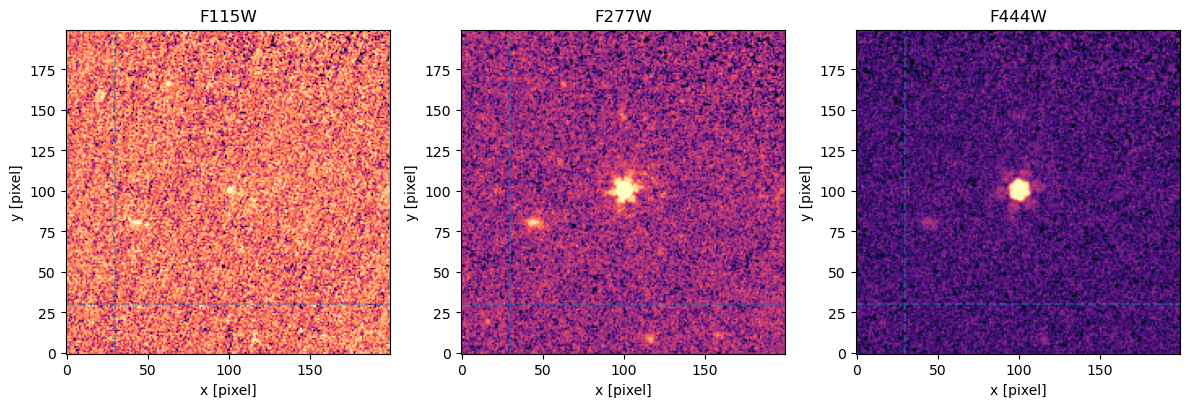

In [5]:
from astropy.io import fits
from astropy.visualization import ImageNormalize, AsinhStretch
import matplotlib.pyplot as plt
import numpy as np

files = [
    "../data/F115W.fits",
    "../data/F277W.fits",
    "../data/F444W.fits"
]

labels = ["F115W", "F277W", "F444W"]

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, filename, label in zip(axes, files, labels):

    data = fits.getdata(filename)
    vmin = np.nanpercentile(data, 1)
    vmax = np.nanpercentile(data, 99.8)

    norm = ImageNormalize(vmin=vmin,vmax=vmax, stretch=AsinhStretch())

    ax.imshow( data,origin="lower",cmap="magma",norm=norm)

    ax.axvline(30, ls="--", alpha=0.5)
    ax.axhline(30, ls="--", alpha=0.5)

    ax.set_title(label)
    ax.set_xlabel("x [pixel]")
    ax.set_ylabel("y [pixel]")

plt.tight_layout()
plt.show()